In [1]:
import gurobipy as gp
from gurobipy import GRB
import random
import csv
import time

# Estruturas de Dados
class Pod:
    def __init__(self, id, resource_usage):
        self.id = id
        self.resource_usage = resource_usage

class Node:
    def __init__(self, id, capacity, opening_cost, allocation_cost):
        self.id = id
        self.capacity = capacity
        self.opening_cost = opening_cost
        self.allocation_cost = allocation_cost

# Gerador de Instâncias
def generate_instance(num_pods, num_nodes):
    pods = [Pod(j, random.randint(1, 10)) for j in range(num_pods)]
    nodes = [Node(i,
                  random.randint(num_pods // (num_nodes + 1), 2 * num_pods),
                  random.randint(1, 4 * num_nodes),
                  random.randint(1, 4 * num_nodes))
             for i in range(num_nodes)]
    return pods, nodes

# Método 1: Simulador do Kube-Scheduler
def kube_scheduler(pods, nodes):
    node_loads = {node.id: 0 for node in nodes}
    mapping = {}
    for pod in pods:
        eligible_nodes = [(node, node.opening_cost) for node in nodes if node_loads[node.id] + pod.resource_usage <= node.capacity]
        if eligible_nodes:
            selected_node = min(eligible_nodes, key=lambda x: x[1])[0]
            node_loads[selected_node.id] += pod.resource_usage
            mapping[pod.id] = selected_node.id
    total_cost = sum(nodes[nid].opening_cost for nid in set(mapping.values()))
    total_cost += sum(nodes[mapping[pid]].allocation_cost for pid in mapping)
    return total_cost, mapping

# Método 2: Programação Inteira Mista
def milp_scheduler(pods, nodes, previous_mapping=None, penalty_weight=10):
    model = gp.Model("PodAllocation")
    model.setParam("OutputFlag", 0)
    model.setParam("MIPGap", 0.01)

    x = model.addVars(len(nodes), vtype=GRB.BINARY, name="x")
    y = model.addVars(len(nodes), len(pods), vtype=GRB.BINARY, name="y")

    # Função Objetivo com penalidade de descontinuação
    obj = gp.quicksum(nodes[i].opening_cost * x[i] +
                      nodes[i].allocation_cost * gp.quicksum(y[i, j] for j in range(len(pods))) +
                      penalty_weight * gp.quicksum(
                          (1 - y[i, j]) if previous_mapping and previous_mapping.get(j) == i else 0
                          for j in range(len(pods)))
                      for i in range(len(nodes)))
    model.setObjective(obj, GRB.MINIMIZE)

    # Restrições
    for j in range(len(pods)):
        model.addConstr(gp.quicksum(y[i, j] for i in range(len(nodes))) == 1)
    for i in range(len(nodes)):
        model.addConstr(gp.quicksum(pods[j].resource_usage * y[i, j] for j in range(len(pods))) <= nodes[i].capacity * x[i])

    model.optimize()

    mapping = {j: i for i in range(len(nodes)) for j in range(len(pods)) if y[i, j].x > 0.5}
    return model.ObjVal, mapping

# Executor de Experimentos
def run_experiments(num_pods_list, num_nodes_list, repetitions=1):
    with open('experiment_results.csv', 'w', newline='') as file:
        writer = csv.writer(file)
        writer.writerow(["num_pods", "num_nodes", "method", "cost", "time_ms"])
        
        for num_pods in num_pods_list:
            for num_nodes in num_nodes_list:
                for _ in range(repetitions):
                    pods, nodes = generate_instance(num_pods, num_nodes)

                    # Método 1
                    start = time.time()
                    cost_kube, mapping_kube = kube_scheduler(pods, nodes)
                    elapsed_kube = (time.time() - start) * 1000
                    writer.writerow([num_pods, num_nodes, "kube_scheduler", cost_kube, elapsed_kube])

                    # Método 2
                    start = time.time()
                    cost_milp, mapping_milp = milp_scheduler(pods, nodes, mapping_kube)
                    elapsed_milp = (time.time() - start) * 1000
                    writer.writerow([num_pods, num_nodes, "milp_scheduler", cost_milp, elapsed_milp])

# Configuração e Execução
num_pods_list = [10, 50, 100, 200, 500, 1000, 5000, 10000]
num_nodes_list = [10, 20, 50, 100, 200]

run_experiments(num_pods_list, num_nodes_list, repetitions=3)


Set parameter Username


Academic license - for non-commercial use only - expires 2026-04-03


/var/folders/r6/7fkdc4jx50j5pnj_6lv0ddnc0000gn/T/ipykernel_4958/3072822561.py:19: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x="num_pods", y="cost", hue="method", ci=None)


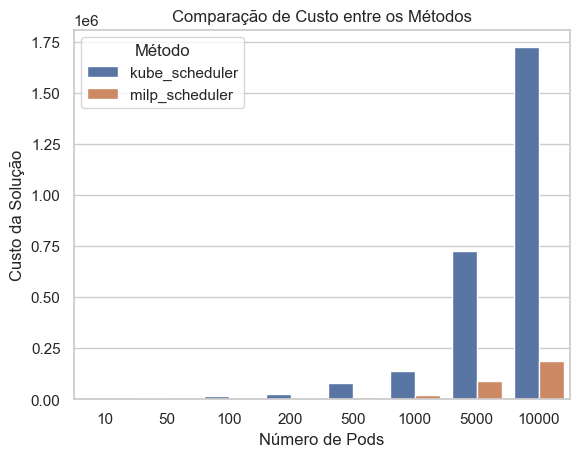

/var/folders/r6/7fkdc4jx50j5pnj_6lv0ddnc0000gn/T/ipykernel_4958/3072822561.py:28: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x="num_pods", y="time_ms", hue="method", ci=None)


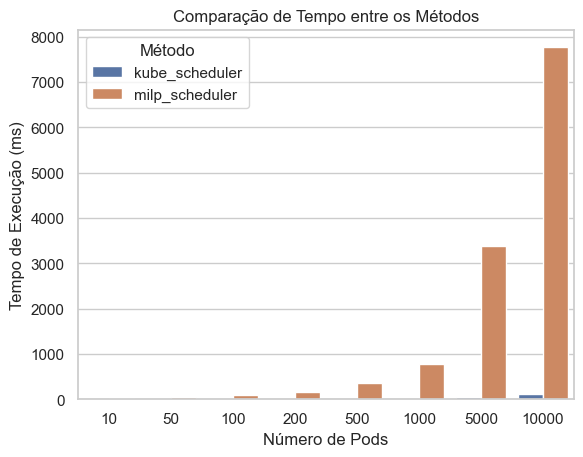

/var/folders/r6/7fkdc4jx50j5pnj_6lv0ddnc0000gn/T/ipykernel_4958/3072822561.py:37: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.catplot(data=df, x="num_nodes", y="cost", hue="method", col="num_pods", kind="bar", ci=None)


<Figure size 640x480 with 0 Axes>

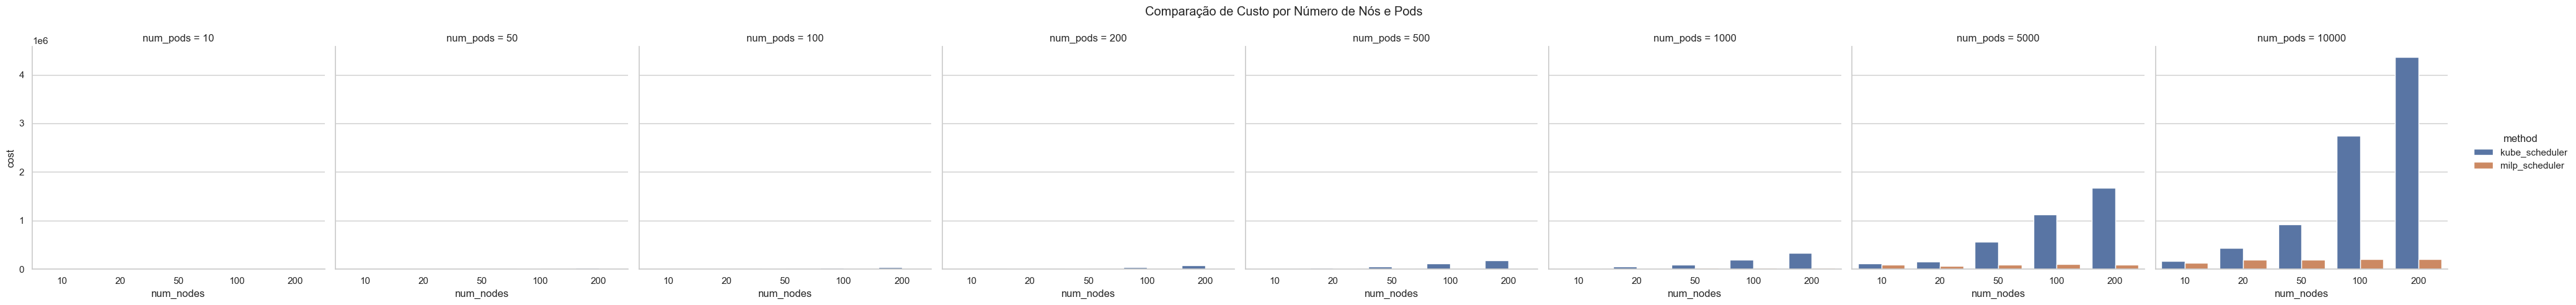

ModuleNotFoundError: No module named 'ace_tools'

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Verifica se o arquivo existe
file_path = 'experiment_results.csv'
if not os.path.exists(file_path):
    raise FileNotFoundError(f"O arquivo '{file_path}' não foi encontrado. Por favor, execute o experimento primeiro.")

# Carrega os dados
df = pd.read_csv(file_path)

# Configura o estilo
sns.set(style="whitegrid")

# Gráfico de comparação de custo
plt.figure()
sns.barplot(data=df, x="num_pods", y="cost", hue="method", ci=None)
plt.title("Comparação de Custo entre os Métodos")
plt.xlabel("Número de Pods")
plt.ylabel("Custo da Solução")
plt.legend(title="Método")
plt.show()

# Gráfico de comparação de tempo
plt.figure()
sns.barplot(data=df, x="num_pods", y="time_ms", hue="method", ci=None)
plt.title("Comparação de Tempo entre os Métodos")
plt.xlabel("Número de Pods")
plt.ylabel("Tempo de Execução (ms)")
plt.legend(title="Método")
plt.show()

# Gráfico detalhado por número de nós
plt.figure()
sns.catplot(data=df, x="num_nodes", y="cost", hue="method", col="num_pods", kind="bar", ci=None)
plt.subplots_adjust(top=0.85)
plt.suptitle("Comparação de Custo por Número de Nós e Pods")
plt.show()

# Exibe o DataFrame para verificação
import ace_tools as tools; tools.display_dataframe_to_user("Resultados do Experimento", df)
